# Flux-pumped λ/4 CPW JPA (QPDK `cpw_jpa`), rebuilt in the Quantcore PDK

**What it is.** A Josephson parametric amplifier used in reflection: a λ/4 CPW resonator whose open end couples
through a capacitor to the signal line and whose far end is shorted to ground through a DC SQUID. The SQUID's
inductance L_s(Φ) = Φ0 / (2π I_c |cos πΦ/Φ0|) tunes the resonance; a shorted pump line next to the SQUID loop
modulates Φ at twice the signal frequency (three-wave mixing) and amplifies (Yamamoto et al., APL 93, 042510 (2008);
the WMI devices of Pogorzalek et al., PR Applied 8, 024012 (2017)).

**Source.** QPDK (gdsfactory/quantum-rf-pdk, MIT): `qpdk/cells/parametric_amplifier.py` (`cpw_jpa`,
`squid_termination`), `qpdk/samples/cpw_jpa_chip.py` and the notebook `vacask_cpw_parametric_amplifier`; cloned
read-only into `build/external/quantum-rf-pdk` (rev e9be61f). QPDK was read, never imported or run.

**This is a Quantcore-PDK rebuild**: our die frame, sapphire, Nb film (with its kinetic inductance), the Nb trilayer
SQUID, our cells and routes, our LOM.

| | QPDK source | Quantcore rebuild (why) |
|---|---|---|
| resonator | 4680 µm λ/4 meander, 10/6 µm CPW, 6 meanders (incl. a 10 µm termination lead) | the same length: qcc meander route + `SquidTermination` lead and landing head |
| coupling | interdigital capacitor, 8 fingers × 50 µm, 2 µm gap, 5 µm fingers (≈ 28 fF) | KQC `FingerCapacitorSquare` with the same fingers (LOM: Igreja–Dias) |
| SQUID | I_c,tot 4.8 µA (L_s(0) = 68.6 pH), loop on the ground side of an etched pocket | **largest PDK trilayer SQUID** (two 2 × 2 µm junctions, I_c,tot ≈ 1.3 µA, L_s(0) ≈ 0.25 nH): the PDK junction rule (J_c 0.16 µA/µm², fingers ≤ 2 µm) cannot reach 4.8 µA; flagged `pdk_rn`, and both values are simulated |
| pump | shorted CPW 200 µm, 2 µm ground strip, short 20 µm past the SQUID | the same, drawn by `SquidTermination` |
| chip | launchers on signal and pump (`cpw_jpa_chip`) | 7.5 × 7.5 mm PDK die, Quantcore `BondPad`s 100 µm from the edge |
| substrate / film | QPDK stack (Si, Al) | sapphire 650 µm, εr 10.25; Nb 200 nm, L_s 0.116 pH/□ |

## 1 · Setup and the PDK
Imports, the PDK facts this chip uses, and the two junction cases (drawn PDK SQUID vs the source's 4.8 µA).

In [2]:
import os, sys
from pathlib import Path
import numpy as np
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
sys.path.insert(0, str(ROOT / "examples" / "designs" / "amplifiers"))
from _common import *                            # netlist tables, simulate_groups, export_sims, snapshots, PDK helpers
from _amplifiers import pdk_facts_md, plot, show_md, table_md, lom_values, c_fF
from quantcore_circuits.designer import Designer
from quantcore_circuits.pdk import get_pdk
from quantcore_circuits.analysis import amplifiers as amp
from quantcore_circuits.analysis.synthesis import cpw_properties
from quantcore_circuits.layouts.others.amplifiers import SquidTermination
from quantcore_circuits.circuit.bridges import junction_from_fingers, rn_from_lj

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
RUN_FEM = False                                  # True: solve the exported jobs with AEDT 2024 R1 (batch, non-graphical)
OUT = Path("examples/designs/amplifiers")
PDK = get_pdk()
show_md(pdk_facts_md(PDK))

| PDK | value |
|---|---|
| substrate | sapphire 650 µm, εr 10.25 |
| film | Nb 200 nm, λ_L 90 nm → L_s 0.116 pH/□ (kinetic, in every CPW / wire formula) |
| junction rule | Nb/AlOx/Nb trilayer, Δ 1.4 meV, J_c 0.163 µA/µm², R_n window 40–50 kΩ, fingers 0.1–2 µm |
| frame | die 7.5 × 7.5 mm standard, margin 100 µm, marker areas 500 µm, brand QCT |
| pad rule | outer etch 100 µm (one dicing-marker width) from the die edge (`edge="auto"`) |
| cheese | PDK band 3 rows of 5 µm squares, 20 µm gap, around the 3/0 keep-outs (unless the original has its own) |
| 3/0 keep-out | routes + 10 µm, components + 24 µm |

In [3]:
BIG_JJ = {"finger_width": 2.0, "second_finger_width": 2.0}   # the largest junction the PDK finger range allows
SQ = SquidTermination.qcc_squid({"junction_params": BIG_JJ})
jv = junction_from_fingers(2.0, 2.0, n=2, pdk=PDK)
LS_SRC = amp.lj_from_ic(4.8e-6) * 1e9                         # nH, QPDK I_c,tot = 4.8 µA
show_md(table_md(["SQUID", "I_c,tot (µA)", "L_s(0) (nH)", "C_J (fF)", "device R_n (kΩ)"], [
    ["drawn: 2 × trilayer 2.0 × 2.0 µm", 2 * jv.ic_each_nA / 1e3, SQ["Ls0_nH"], SQ["Cj_fF"], jv.rn_kohm],
    ["QPDK source", 4.8, LS_SRC, None, rn_from_lj(LS_SRC) / 1e3],
]))
JUNCTION = {"Lj_nH": SQ["Ls0_nH"], "Cj_fF": SQ["Cj_fF"]}      # on the instance: the LOM uses it, DRC flags pdk_rn

| SQUID | I_c,tot (µA) | L_s(0) (nH) | C_J (fF) | device R_n (kΩ) |
|---|---|---|---|---|
| drawn: 2 × trilayer 2.0 × 2.0 µm | 1.303 | 0.2525 | 400 | 1.688 |
| QPDK source | 4.8 | 0.06856 | – | 0.4581 |

## 2 · The die and frame
A standard 7.5 × 7.5 mm Quantcore die: dicing L-markers, corner marker areas, the 100 µm design margin and the
device ID are drawn by the chip frame.

In [4]:
W = H = 7500
YC = 3750
d = Designer("qpdk_cpw_jpa", box=(0, 0, W, H), chip={"name_chip": "JPA"}, live=LIVE)

## 3 · Pads (the 100 µm rule)
Two Quantcore `BondPad`s: the signal pad on the west edge and the pump pad on the east edge. `edge="auto"` slides
each pad perpendicular to its die edge until its outer etch is the PDK `pad_edge` (100 µm) from it.

In [5]:
X_CC, X_ST = 3250, 3900                          # capacitor centre, SQUID termination (lead start): a compact
                                                 # 6-meander resonator between them, as QPDK draws it
with d.batch():
    d.add("P_SIG", "BondPad", at=(400, YC), rot=-90, edge="auto")
    d.add("P_PUMP", "BondPad", at=(7100, YC - 400), rot=90, edge="auto")

## 4 · Components
* `CC` — KQC `FingerCapacitorSquare`, the QPDK coupling capacitor (8 fingers × 50 µm, 5 µm wide, 2 µm gaps).
* `ST` — Quantcore `SquidTermination`: the lead (10 µm) ends on a 6 × 28 µm landing head in a 34 µm pocket; the
  trilayer SQUID bridges the 20 µm junction gap to ground (its two straight fingers sit ±8 µm off-axis, on the
  head); the pump CPW runs past the ground side, shorted 20 µm beyond the SQUID axis. Ports: `a` (resonator side),
  `pump`; `squid_a` / `squid_b` mark the junction ends for FEM.

In [6]:
with d.batch():
    cc = d.add("CC", "FingerCapacitorSquare", at=(X_CC, YC), finger_number=8, finger_length=50, finger_width=5,
               finger_gap=2)
    st = d.add("ST", "SquidTermination", at=(X_ST, YC), junction=JUNCTION, junction_params=BIG_JJ)
print({p: (round(v.pos.x, 1), round(v.pos.y, 1), v.angle) for p, v in st.ports.items()})

{'pump': (49.0, -180.0, -90.0), 'a': (0.0, 0.0, 180.0), 'squid_a': (16.0, 0.0, None), 'squid_b': (36.0, 0.0, None)}


## 5 · Routes
* `L_SIG`: 50 Ω feed from the signal pad to the capacitor.
* `JPA`: the λ/4 resonator, a fixed-length meander from the capacitor to the termination. QPDK's 4680 µm include
  the 10 µm termination lead; ours has a 10 µm lead and a 6 µm head, so the route is 4680 − 16 = 4664 µm.
* `L_PUMP`: the pump line from the termination's pump port (facing south) to the east pad.

`meanders=6` keeps QPDK's six meander sections. Six turns need 2·r·(6 + 1) µm of straight between the capacitor and
the termination (478 µm here), so the bend radius is 30 µm; with a larger `r` the router lays fewer, taller turns
(same length) and warns.

In [7]:
L_RES = 4680.0
with d.batch():
    d.route("L_SIG", "P_SIG.a", "CC.a")
    d.route("JPA", "CC.b", "ST.a", meander=L_RES - 16.0, r=30).set(meanders=6)
    xp, yp = port_xy(d, "ST.pump")
    d.route("L_PUMP", "ST.pump", "P_PUMP.a", nodes=[(xp, YC - 400)], r=80)
d.targets(JPA={"f_GHz": 6.07})                    # QPDK SAX resonance at Φ = 0 (its stack, its SQUID)
d.sim_group("jpa", ["CC", "JPA", "ST"], margin_um=150, analyses=["q3d_cmatrix", "eigenmode_epr"])
d.sim_group("termination", ["ST"], margin_um=80, analyses=["q3d_cmatrix"])
if not LIVE:
    d.show()
DESIGN = d.save(OUT / "qpdk_cpw_jpa.json")
print(d, "→", DESIGN)
print({k: round(v, 1) for k, v in d.result.route_lengths().items()})

<Designer qpdk_cpw_jpa: 4 instances, 3 routes, live=False> → examples\designs\amplifiers\qpdk_cpw_jpa.json
{'L_SIG': 1973.5, 'JPA': 4664.0, 'L_PUMP': 2511.7}


## 6 · DRC
Errors would block fab; warnings are layout hints (`dangling_port` on `squid_a` / `squid_b`: junction attachment
points, not route ends). **PDK design warnings** are flagged, never enforced: here `pdk_rn` — the SQUID's device
R_n (≈ 1.7 kΩ) is far below the qubit window 40–50 kΩ, as an amplifier junction must be.

In [8]:
print(d.drc())
show_md(pdk_report(d))

warning dangling_port ST.squid_a is not connected (no route or snap)
warning dangling_port ST.squid_b is not connected (no route or snap)
design  pdk_rn        ST: junction R_n 1.7 kΩ is outside the PDK window 40–50 kΩ (L_J 0.25254 nH)


| check | value |
|---|---|
| cheese | PDK band (drawn in the build) |
| content centre − die centre | (+0, -200) µm |
| junction types | Quantcore Squid × 1 |
| PDK design warnings | 1 (pdk_rn × 1) |
| pdk_rn | ST: junction R_n 1.7 kΩ is outside the PDK window 40–50 kΩ (L_J 0.25254 nH) |

## 7 · Netlist and LOM
The builder joins `L_SIG` (a wire: pad → capacitor), the `FingerCapacitorSquare` π network, and one λ/4 `TLres`
made of the `JPA` route plus the termination's lead. `SquidTermination`'s LOM puts the SQUID in as the line's
shorted end at its **inductive equivalent length** ℓ_eq = lead + head + L_s/L' (L' of the 10/6 µm CPW with the Nb
kinetic inductance), so f_r ≈ f_λ/4 / (1 + L_s / L'ℓ). The pump line is a control (flux), no circuit element.

In [9]:
lb = d.lom()
show_netlist(lb)

**3 nodes · 5 branches · 1 controls · 0 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `CC.a` | `P_SIG.pad`, `CC.a` |
| `CC.b` | `CC.b`, `ST.lead` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `Port_P_SIG` | R | `CC.a` – `gnd` | 50 Ω |
| `C_CC` | C | `CC.a` – `CC.b` | 28.2 fF |
| `C_CC_a` | C | `CC.a` – `gnd` | 6.6 fF |
| `C_CC_b` | C | `CC.b` – `gnd` | 6.6 fF |
| `JPA` | TLres | `CC.b` – `gnd` | lambda/4, 5257 µm, 5.993 GHz |

| control | kind | target | line | length (µm) |
|---|---|---|---|---|
| `L_PUMP` | flux_bias | `J_ST` | `L_PUMP` | 2512 |

**Unconnected ports:** none

**Builder notes:**

- ST: SQUID L_s = 0.2525 nH at Φ = 0 Φ0 (design) → 577 µm of 10/6 µm CPW at the shorted end (L' 437 nH/m incl. kinetic); the SQUID's Kerr / three-wave mixing is not in the lumped circuit (analysis.amplifiers)
- JPA: one lambda/4 line of 5257 µm through ['ST'] and route(s) ['JPA']; pass-through section(s) ['ST'] enter by (equivalent) length only, the width step is not modelled (one Z0, a/b 10/6 µm)
- Port_P_PUMP: both ends on gnd after merging conductors (dropped)

## 8 · LOM simulation: resonance and Q
**(a) QuCat normal modes** of the selection pad + feed + capacitor + resonator: the JPA mode's frequency and its
external linewidth through the 50 Ω pad.

In [10]:
res = simulate_groups(d, {"JPA": ["P_SIG", "L_SIG", "CC", "JPA", "ST"]}, max_modes=1)
display(Markdown(modes_md(res["JPA"])))

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| JPA | resonator | 5.7358 | 19.8 | 0.0 | JPA 1.00 |

**(b) The distributed model** (`analysis.amplifiers.cpw_jpa_s11`): port — C_c — λ/4 CPW (Z0, v_p with kinetic
inductance) — L_s(Φ) to ground, the exact transmission-line formula; f0 at the steepest reflection phase,
κ/2π = 4 / max|dφ/df|. Drawn PDK SQUID next to the QPDK source SQUID (same layout, same C_c).

In [11]:
cpw = cpw_properties(6.5, 10, 6, PDK.name)
caps = {n: c_fF(v) for n, v in lom_values(lb, "C").items() if "CC" in n}
CC_FF = max(caps.values())                       # the series (mutual) capacitance of the finger capacitor
LENGTH = d.result.route_lengths()["JPA"] + 16.0  # route + termination lead and head
f = np.linspace(4.0e9, 7.5e9, 350001)

def jpa(ls_nH, cc_fF=CC_FF, length=LENGTH):
    return amp.resonance(f, amp.cpw_jpa_s11(f, cc_fF * 1e-15, cpw["Z0_ohm"], cpw["vp_m_s"], length, ls_nH * 1e-9))

rows = []
for label, ls in (("drawn PDK SQUID", SQ["Ls0_nH"]), ("QPDK source SQUID", LS_SRC), ("no SQUID (bare λ/4)", 0.0)):
    f0, k = jpa(ls)
    rows.append([label, ls, f0 / 1e9, k / 1e6, f0 / k])
show_md(f"Z0 {cpw['Z0_ohm']:.1f} Ω, v_p {cpw['vp_m_s']:.3e} m/s (α_k {cpw['alpha_k']:.1%}), C_c {CC_FF:.1f} fF "
        f"(LOM), ℓ {LENGTH:.0f} µm\n\n" + table_md(["SQUID", "L_s(0) (nH)", "f0 (GHz)", "κ/2π (MHz)", "Q_ext"], rows))

Z0 55.1 Ω, v_p 1.260e+08 m/s (α_k 3.1%), C_c 28.2 fF (LOM), ℓ 4680 µm

| SQUID | L_s(0) (nH) | f0 (GHz) | κ/2π (MHz) | Q_ext |
|---|---|---|---|---|
| drawn PDK SQUID | 0.2525 | 5.784 | 21.24 | 272.3 |
| QPDK source SQUID | 0.06856 | 6.262 | 26.88 | 233 |
| no SQUID (bare λ/4) | 0 | 6.463 | 29.54 | 218.8 |

**(c) Flux tuning** f0(Φ) for both SQUIDs, and the operating point Φ = 0.3 Φ0 that QPDK uses for the gain.

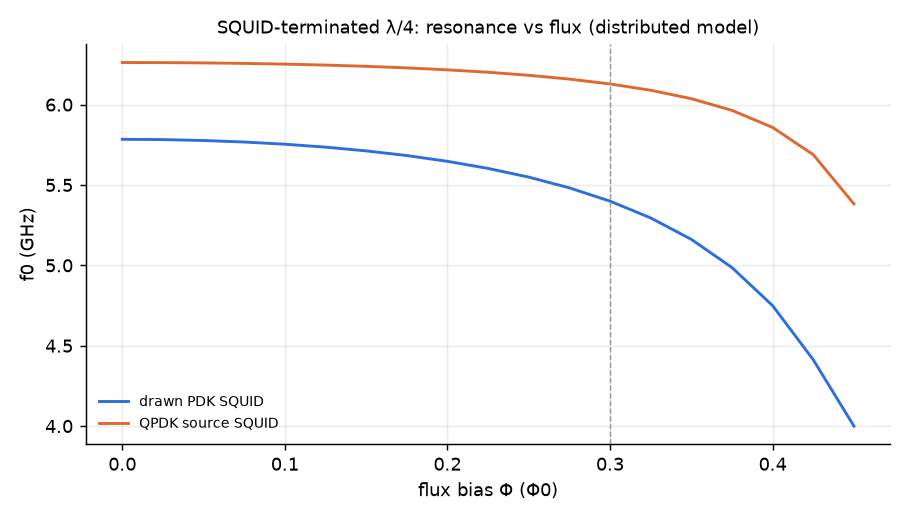

| SQUID | f0 at 0.3 Φ0 (GHz) | κ/2π (MHz) | df0/dΦ (GHz/Φ0) | threshold Φ_p (mΦ0) |
|---|---|---|---|---|
| drawn PDK SQUID | 5.399 | 17.38 | -3.72 | 4.673 |
| QPDK source SQUID | 6.129 | 25.21 | -1.38 | 18.27 |

In [12]:
phis = np.linspace(0, 0.45, 19)
curves = {lab: [jpa(float(amp.squid_ls(ls, p)))[0] / 1e9 for p in phis]
          for lab, ls in (("drawn PDK SQUID", SQ["Ls0_nH"]), ("QPDK source SQUID", LS_SRC))}
plot(OUT / "qpdk_cpw_jpa_tuning.png", [(phis, v, k) for k, v in curves.items()], "flux bias Φ (Φ0)",
     "f0 (GHz)", "SQUID-terminated λ/4: resonance vs flux (distributed model)", vline=0.3)
OP = {}
for lab, ls in (("drawn PDK SQUID", SQ["Ls0_nH"]), ("QPDK source SQUID", LS_SRC)):
    fa, k = jpa(float(amp.squid_ls(ls, 0.3)))
    fb, _ = jpa(float(amp.squid_ls(ls, 0.301)))
    OP[lab] = {"f0": fa, "kappa": k, "df_dphi": (fb - fa) / 1e-3}
show_md(table_md(["SQUID", "f0 at 0.3 Φ0 (GHz)", "κ/2π (MHz)", "df0/dΦ (GHz/Φ0)", "threshold Φ_p (mΦ0)"],
                 [[k, v["f0"] / 1e9, v["kappa"] / 1e6, v["df_dphi"] / 1e9, 1e3 * v["kappa"] / abs(v["df_dphi"])]
                  for k, v in OP.items()]))

**(d) Gain vs pump** (single-mode flux-pumped paramp, `analysis.amplifiers.flux_pumped_gain`): pump at 2 f0, a
modulation δω = 2π |df0/dΦ| Φ_p; r = δω/κ; peak gain ((1 + r²)/(1 − r²))², threshold r = 1. QPDK's harmonic
balance gives somewhat less (the line's higher modes take part); this is the single-mode bound.

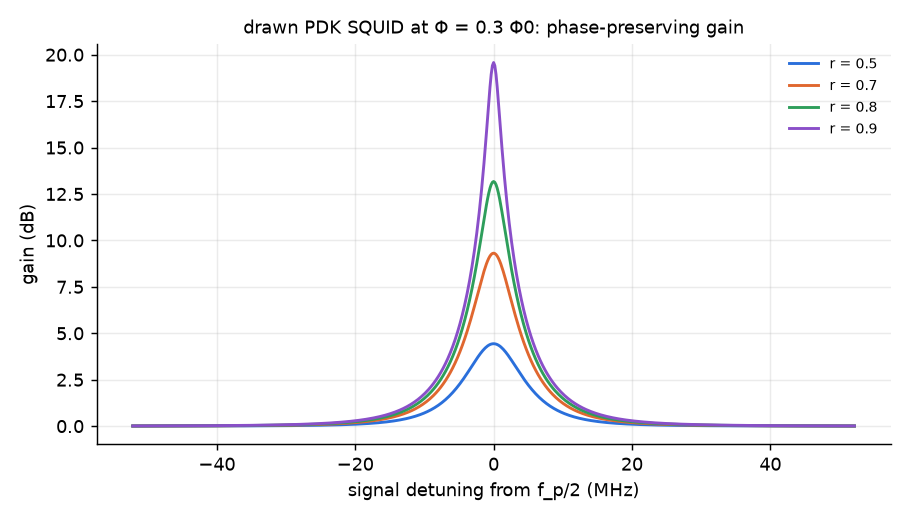

| r | peak gain (dB) | pump flux Φ_p (mΦ0) | −3 dB bandwidth (MHz) |
|---|---|---|---|
| 0.5 | 4.437 | 2.337 | 13.56 |
| 0.7 | 9.312 | 3.271 | 5.563 |
| 0.8 | 13.17 | 3.738 | 3.477 |
| 0.9 | 19.58 | 4.206 | 1.738 |

In [13]:
op = OP["drawn PDK SQUID"]
det = np.linspace(-3, 3, 601) * op["kappa"]
plot(OUT / "qpdk_cpw_jpa_gain.png",
     [(det / 1e6, amp.db(amp.flux_pumped_gain(det, op["kappa"], r)), f"r = {r}") for r in (0.5, 0.7, 0.8, 0.9)],
     "signal detuning from f_p/2 (MHz)", "gain (dB)", "drawn PDK SQUID at Φ = 0.3 Φ0: phase-preserving gain")
show_md(table_md(["r", "peak gain (dB)", "pump flux Φ_p (mΦ0)", "−3 dB bandwidth (MHz)"], [
    [r, float(amp.db(amp.flux_pumped_peak_gain(r))), 1e3 * r * op["kappa"] / abs(op["df_dphi"]),
     float(np.ptp(det[amp.db(amp.flux_pumped_gain(det, op["kappa"], r)) >= amp.db(amp.flux_pumped_peak_gain(r)) - 3]))
     / 1e6] for r in (0.5, 0.7, 0.8, 0.9)]))

## 9 · FEM: send the jobs
A Q3D C-matrix job of capacitor + resonator + termination (replaces the capacitor's estimate) and of the
termination alone (the SQUID pocket and pump strip), and an eigenmode job of the resonator with the SQUID as a
lumped inductor at `squid_a` / `squid_b` (L_J from the instance's junction). `RUN_FEM = False`: export only. With
`RUN_FEM = True` and AEDT 2024 R1 found, `solve_job(job)` runs each batch, non-graphical (never a user's open AEDT).
The pump-to-loop mutual inductance M needs a driven / magnetostatic run (not exported here; QPDK leaves it to EM).

In [14]:
jobs = export_sims(DESIGN, ["jpa", "termination"])
jobs_eig = export_sims(DESIGN, ["jpa"], analysis="eigenmode_epr")
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))
if RUN_FEM:
    from quantcore_circuits.sim_tools import solve_job
    for job, _ in list(jobs.values()) + list(jobs_eig.values()):
        solve_job(job)

| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| jpa | `build/jobs/qpdk_cpw_jpa_jpa_q3d_cmatrix` | 1 · junction · `ST.junction`<br>2 · waveguide · `CC.b`<br>3 · waveguide · `ST.a`<br>4 · edge · `L_PUMP`<br>5 · edge · `L_SIG` | `ST.island`, `CC.b`, `L_SIG` |
| termination | `build/jobs/qpdk_cpw_jpa_termination_q3d_cmatrix` | 1 · junction · `ST.junction`<br>2 · edge · `JPA`<br>3 · edge · `L_PUMP` | `ST.island` |
| jpa | `build/jobs/qpdk_cpw_jpa_jpa_eigenmode_epr` | 1 · junction · `ST.junction`<br>2 · edge_lumped · `L_PUMP`<br>3 · edge_lumped · `L_SIG` | `ST.island`, `L_PUMP`, `L_SIG` |

## 10 · Bring it back
When `build/jobs/<job>/results/results.json` exists, `fill(model, design, job)` replaces the LOM capacitances by
the C-matrix (by net name) and the mode table above is recomputed; otherwise the estimates stand.

In [15]:
from quantcore_circuits.circuit.fill import fill
job = jobs["jpa"][0]
if (Path(job) / "results" / "results.json").exists():
    filled = fill(lb.model, d.design, job)
    show_md(f"C-matrix applied from `{job}`")
else:
    show_md(f"No results in `{job}` yet: the C_c and line values are the analytic estimates.")

No results in `build\jobs\qpdk_cpw_jpa_jpa_q3d_cmatrix` yet: the C_c and line values are the analytic estimates.

## 11 · Iterate: a smaller SQUID
One property: the SQUID's finger width 2.0 → 1.2 µm (junction area ÷ 2.8, L_s × 2.8). Rebuild, re-run the LOM and
the distributed model: the participation L_s / (L_s + L'ℓ) grows, f0 drops, the flux tuning steepens.

In [16]:
before = (res["JPA"].modes[0].f_GHz, *jpa(SQ["Ls0_nH"]))
SMALL = {"finger_width": 1.2, "second_finger_width": 1.2}
sq2 = SquidTermination.qcc_squid({"junction_params": SMALL})
d["ST"].set(junction_params=SMALL, junction={"Lj_nH": sq2["Ls0_nH"], "Cj_fF": sq2["Cj_fF"]})
res2 = simulate_groups(d, {"JPA": ["P_SIG", "L_SIG", "CC", "JPA", "ST"]}, max_modes=1)
after = (res2["JPA"].modes[0].f_GHz, *jpa(sq2["Ls0_nH"]))
show_md(table_md(["SQUID fingers", "L_s(0) (nH)", "LOM f (GHz)", "distributed f0 (GHz)", "κ/2π (MHz)"], [
    ["2.0 × 2.0 µm", SQ["Ls0_nH"], before[0], before[1] / 1e9, before[2] / 1e6],
    ["1.2 × 1.2 µm", sq2["Ls0_nH"], after[0], after[1] / 1e9, after[2] / 1e6]]))
d["ST"].set(junction_params=BIG_JJ, junction=JUNCTION)   # back to the design values
DESIGN = d.save(OUT / "qpdk_cpw_jpa.json")

| SQUID fingers | L_s(0) (nH) | LOM f (GHz) | distributed f0 (GHz) | κ/2π (MHz) |
|---|---|---|---|---|
| 2.0 × 2.0 µm | 0.2525 | 5.736 | 5.784 | 21.24 |
| 1.2 × 1.2 µm | 0.7015 | 4.832 | 4.921 | 13.36 |

## 12 · Build and export
The saved design (`qpdk_cpw_jpa.json`) is what `qcc build` / `qcc mask` read. `export_fab` writes the PDK fab
layers (negative mask; corner rounding and the PDK cheese band); simulation exports never carry cheese.
CLI: `qcc build examples/designs/amplifiers/qpdk_cpw_jpa.json`, `qcc mask examples/designs/amplifiers/qpdk_cpw_jpa.json`.

In [17]:
from quantcore_circuits.layouts.wafers.fab_export import export_fab
if d.result is None:
    d.show()
fab = {}
export_fab(d.result, Path("build") / f"{d.design.name}_fab.oas", report=fab)
LAYERS = PDK.fab_layers
show_md(f"cheese: {fab.get('cheese_source')}, holes {fab.get('cheese_holes')}\n\n" + table_md(
    ["fab layer", "PDK name", "polygons"],
    [[f"{LAYERS[k].layer}/{LAYERS[k].datatype}", k, n] for k, n in sorted(fab["written"].items(),
                                                                          key=lambda kv: LAYERS[kv[0]].layer)]))

cheese: build, holes 2291

| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 2296 |
| 2/0 | JJ_STRAIGHT | 1 |
| 3/0 | M3 | 2295 |
| 4/0 | JJ_BENT | 3 |
| 50/0 | HSQ | 4 |
| 51/0 | SPACER_1 | 4 |
| 52/0 | SPACER_2 | 4 |
| 53/0 | SPACER_3 | 4 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

## 13 · Snapshots
The full die; the SQUID termination (pocket, landing head, trilayer SQUID, pump line and its 2 µm ground strip);
the coupling capacitor; QPDK's own reference GDS of `cpw_jpa` (`tests/gds_ref/cpw_jpa.gds`, rendered read-only).

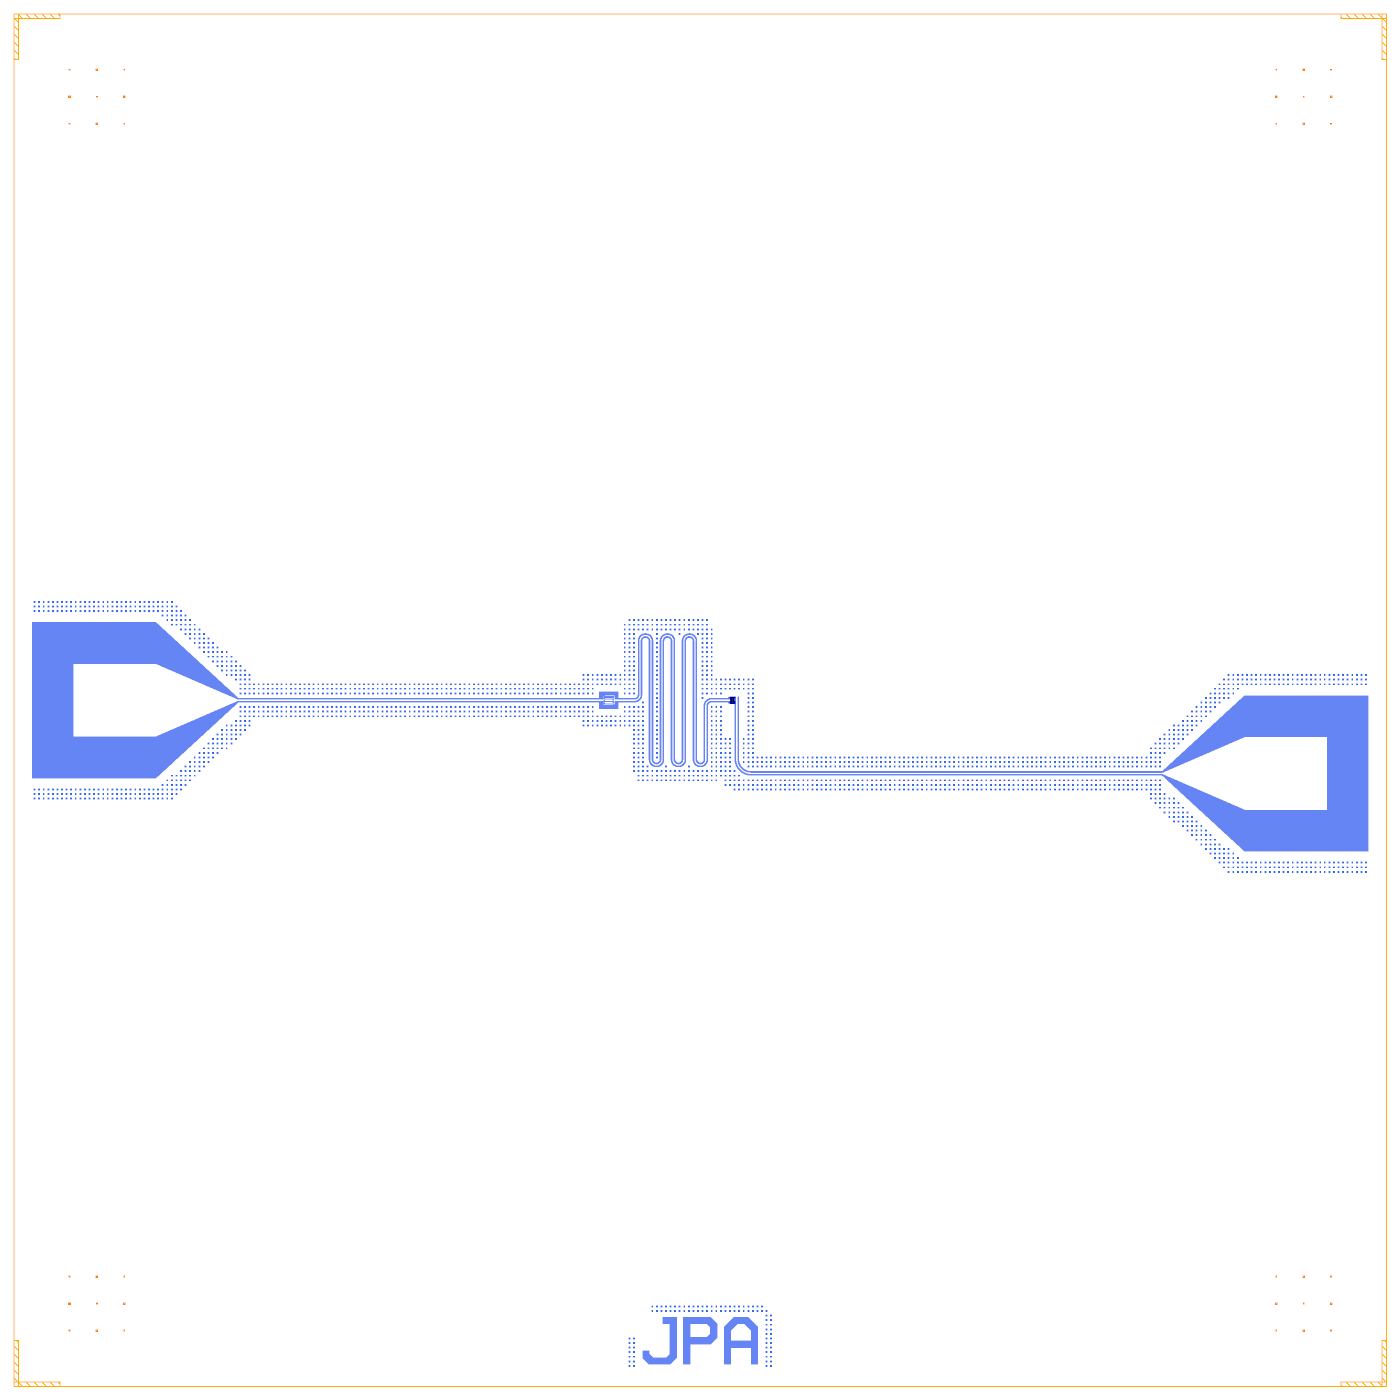

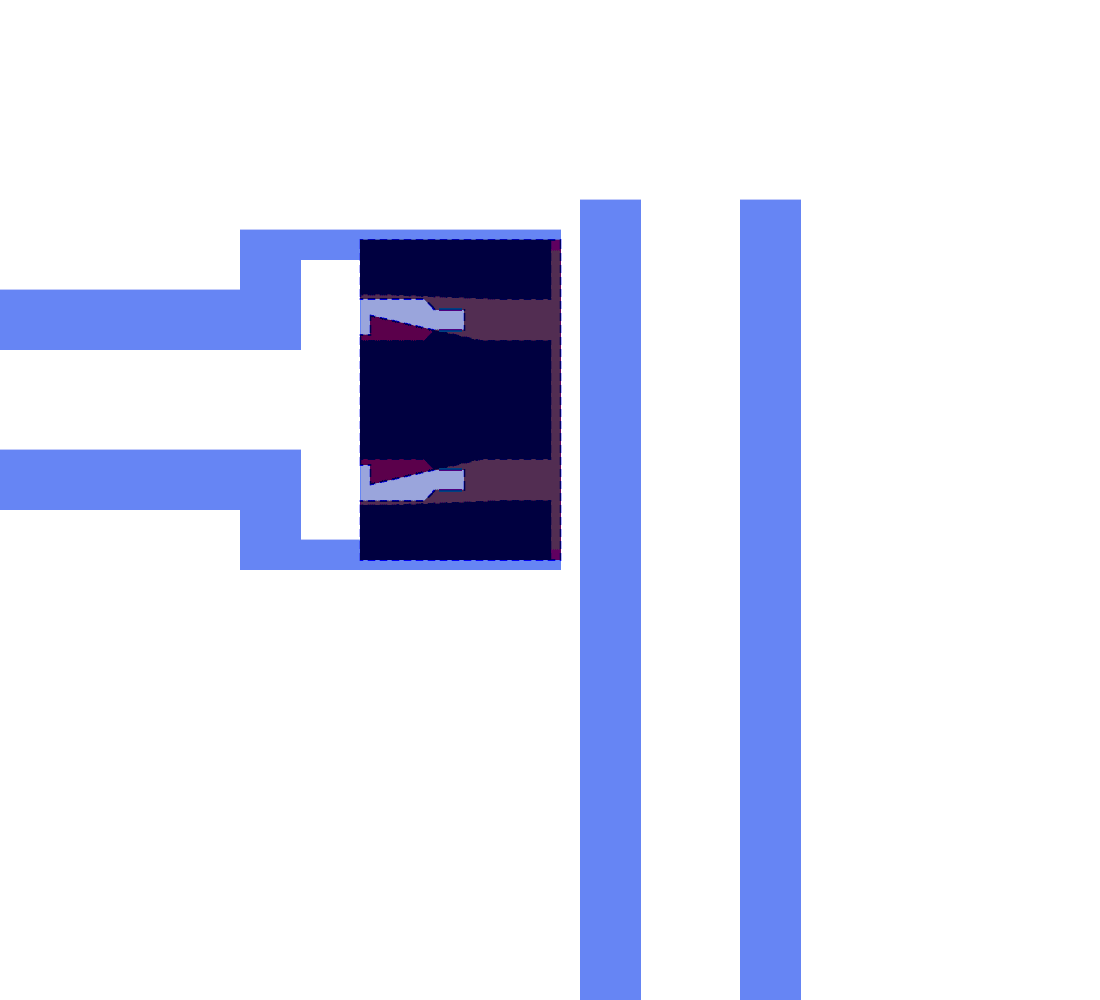

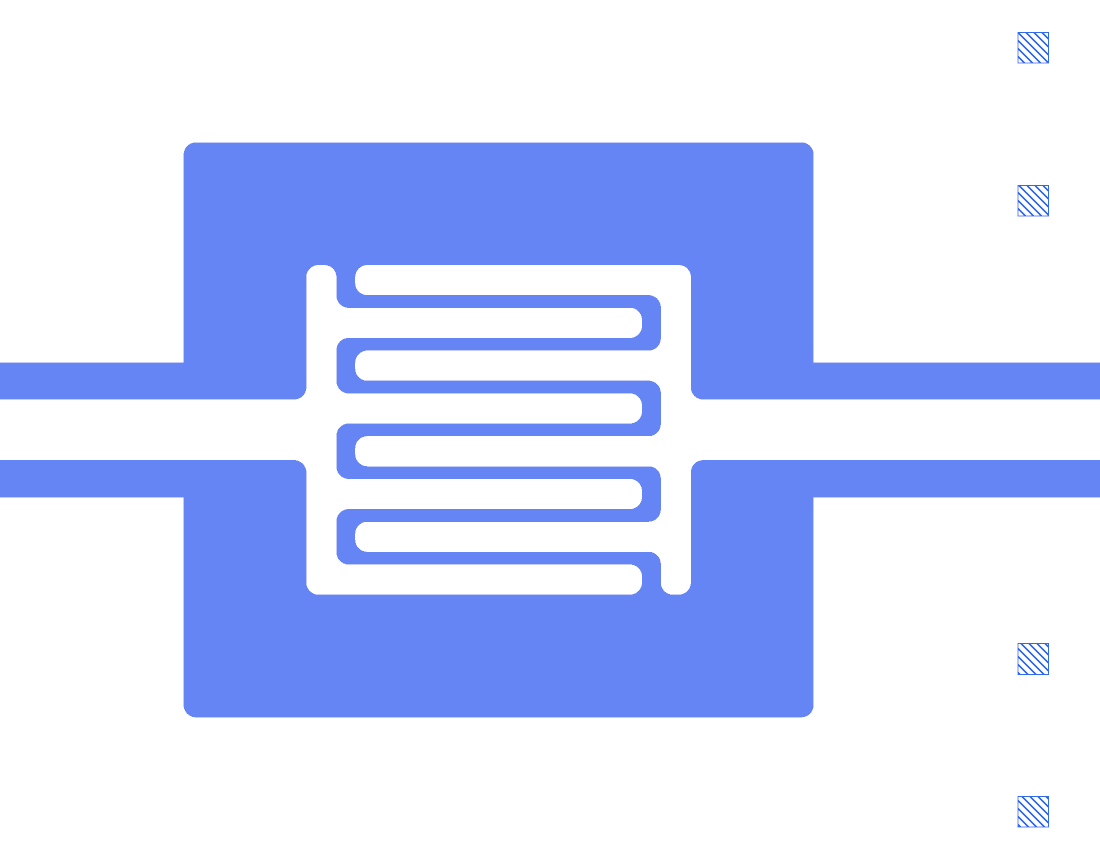

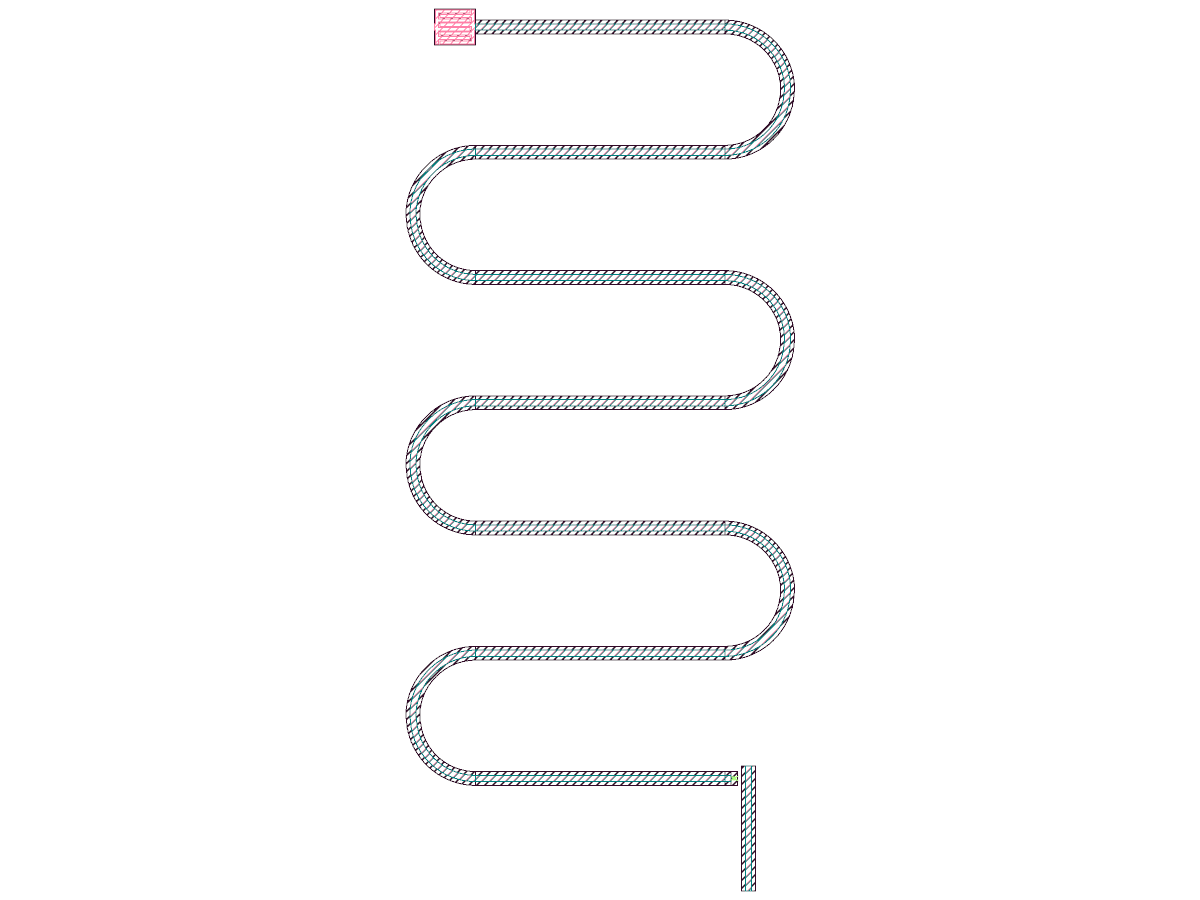

In [18]:
show_snapshot(d, OUT / "qpdk_cpw_jpa.png", size=(1400, 1400))
x, y = port_xy(d, "ST.a")
show_snapshot(d, OUT / "qpdk_cpw_jpa_squid.png", box=(x - 20, y - 60, x + 90, y + 40), size=(1100, 1000), width=440)
x, y = port_xy(d, "CC.a")
show_snapshot(d, OUT / "qpdk_cpw_jpa_cap.png", box=(x - 30, y - 70, x + 150, y + 70), size=(1100, 860), width=440)
ref = ROOT / "build/external/quantum-rf-pdk/tests/gds_ref/cpw_jpa.gds"
if ref.exists():
    from quantcore_circuits.live.snapshot import snapshot
    display(Image(filename=str(snapshot(str(ref), OUT / "qpdk_cpw_jpa_original.png", size=(1200, 900))), width=480))

## 14 · Summary
* **Matches the source:** topology (C_c → 4680 µm λ/4 → SQUID to ground, shorted pump past the loop), the
  capacitor's fingers, the pump geometry (200 µm, 2 µm strip, 20 µm offset), the 10/6 µm CPW.
* **Differs:** the SQUID is the largest PDK trilayer SQUID (≈ 1.3 µA instead of 4.8 µA): with L_s ≈ 0.25 nH its
  participation is ≈ 4× larger, so f0 sits lower and tunes faster (both cases are tabulated above); sapphire and the
  Nb kinetic inductance shift f0 against QPDK's 6.07 GHz; bond pads instead of QPDK launchers.
* **PDK design warnings:** `pdk_rn` on `ST` (device R_n ≈ 1.7 kΩ, qubit window 40–50 kΩ) — expected for an
  amplifier; an amplifier junction process (higher J_c) is a PDK request.
* **Not modelled:** the pump-to-loop mutual inductance (EM), the line's higher modes in the gain (QPDK's HB shows
  they cost gain), SQUID loop inductance.